In [18]:
   %pip install pandas matplotlib openpyxl

Note: you may need to restart the kernel to use updated packages.


In [19]:
import os
print(os.getcwd())
print(os.listdir())

c:\Users\raffy\Documents\kelompok3
['.ipynb_checkpoints', 'analisis.ipynb', 'app.py', 'game-online-favorit-pengguna-internet-indonesia-2026-mobile-legends-teratas.xlsx', 'Untitled.ipynb', 'venv-kelompok3']


In [20]:
import pandas as pd
import matplotlib.pyplot as plt
 
INPUT_FILE = "game-online-favorit-pengguna-internet-indonesia-2026-mobile-legends-teratas.xlsx"
OUTPUT_FILE = "game_favorit_clean.csv"
OUTPUT_PLOT = "eda_game.png"

In [21]:
def load_data(path: str) -> pd.DataFrame:
    """Baca file Excel mentah."""
    return pd.read_excel(path)

In [22]:
def check_raw(df: pd.DataFrame) -> None:
    """Tampilkan kondisi awal data."""
    print("=== PEMERIKSAAN DATA MENTAH ===")
    print(df.to_string(index=False))
    print("\nDuplikat baris :", df.duplicated().sum())
    print("Duplikat nama  :", df["Nama Data"].duplicated().sum())
    print("Nilai kosong   :", df.isna().sum().sum())
    print("Total nilai    :", round(df["Nilai"].sum(), 1))

In [23]:
def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    """Rapikan nama kolom, tipe data, dan tandai baris gabungan 'Lainnya'."""
    clean = df.copy()
    clean.columns = ["no", "game", "persentase"]
    clean["game"] = clean["game"].str.strip()
    clean["persentase"] = clean["persentase"].astype(float)
    clean["kategori_data"] = clean["game"].map(
        lambda g: "Gabungan (Lainnya)" if g == "Lainnya" else "Game spesifik"
    )
    return clean

In [24]:
def rank_games(clean: pd.DataFrame) -> pd.DataFrame:
    """Peringkat game (tanpa 'Lainnya') beserta persen kumulatif."""
    games = clean[clean["game"] != "Lainnya"].sort_values(
        "persentase", ascending=False
    ).copy()
    games["persen_kumulatif"] = games["persentase"].cumsum().round(1)
    games["selisih_dari_nomor_1"] = (
        games["persentase"].iloc[0] - games["persentase"]
    ).round(1)
    games["kelompok"] = pd.cut(
        games["persentase"],
        bins=[0, 5, 20, 100],
        labels=["Kecil (<5%)", "Menengah (5-20%)", "Besar (>20%)"],
    )
    return games

In [25]:
def summarize(games: pd.DataFrame) -> None:
    """Cetak tabel ringkasan dan agregasi per kelompok."""
    print("\n=== PERINGKAT GAME ===")
    cols = ["game", "persentase", "persen_kumulatif", "selisih_dari_nomor_1"]
    print(games[cols].to_string(index=False))
 
    print("\n=== STATISTIK DESKRIPTIF ===")
    print(games["persentase"].describe().round(2))
 
    per_group = games.groupby("kelompok", observed=True).agg(
        jumlah_game=("game", "count"),
        total_persen=("persentase", "sum"),
        rata2_persen=("persentase", "mean"),
    ).round(2)
    print("\n=== AGREGASI PER KELOMPOK ===")
    print(per_group)
 
    first, second = games.iloc[0], games.iloc[1]
    print(f"\n{first['game']} memimpin dengan {first['persentase']}%")
    print(f"Dua game teratas menguasai {games.head(2)['persentase'].sum():.1f}% dari total")
    print(f"Rasio nomor 1 : nomor 2 = {first['persentase'] / second['persentase']:.2f}x")

In [26]:
def plot(games: pd.DataFrame, path: str) -> None:
    """Grafik batang horizontal persentase tiap game."""
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh(games["game"], games["persentase"])
    ax.invert_yaxis()
    for i, value in enumerate(games["persentase"]):
        ax.text(value + 0.3, i, f"{value}%", va="center")
    ax.set(xlabel="Persentase (%)",
           title="Game online favorit pengguna internet Indonesia 2026")
    fig.tight_layout()
    fig.savefig(path, dpi=150)

=== PEMERIKSAAN DATA MENTAH ===
 No        Nama Data  Nilai
  1   Mobile Legends   40.5
  2        Free Fire   24.2
  3           Roblox   11.3
  4             PUBG    9.3
  5 Candy Crush Saga    5.4
  6      FIFA Mobile    2.3
  7        Minecraft    1.8
  8          Lainnya    5.1

Duplikat baris : 0
Duplikat nama  : 0
Nilai kosong   : 0
Total nilai    : 99.9

=== PERINGKAT GAME ===
            game  persentase  persen_kumulatif  selisih_dari_nomor_1
  Mobile Legends        40.5              40.5                   0.0
       Free Fire        24.2              64.7                  16.3
          Roblox        11.3              76.0                  29.2
            PUBG         9.3              85.3                  31.2
Candy Crush Saga         5.4              90.7                  35.1
     FIFA Mobile         2.3              93.0                  38.2
       Minecraft         1.8              94.8                  38.7

=== STATISTIK DESKRIPTIF ===
count     7.00
mean     13.54


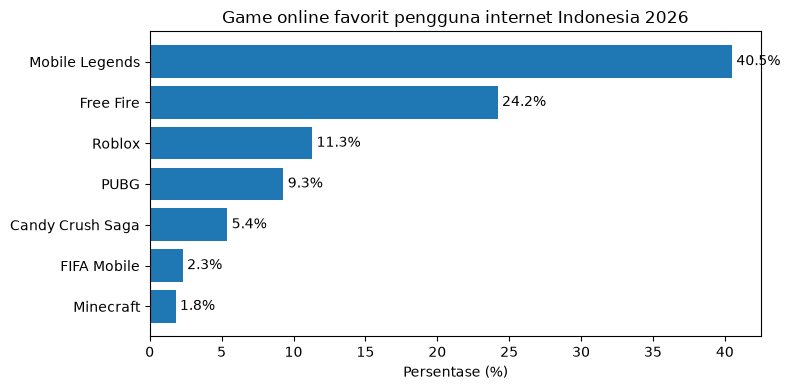

In [27]:
def main() -> None:
    df = load_data(INPUT_FILE)
    check_raw(df)
 
    clean = clean_data(df)
    games = rank_games(clean)
    summarize(games)
    plot(games, OUTPUT_PLOT)
 
    clean.to_csv(OUTPUT_FILE, index=False)
    print(f"\nTersimpan: {OUTPUT_FILE} dan {OUTPUT_PLOT}")
 
 
if __name__ == "__main__":
    main()